This notebook shows best fine-tuned SAM model performance.

In [2]:
from pathlib import Path
import sys

root_dir = Path.cwd().resolve().parents[1]
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from materials_vision.evaluation.inference import build_segmenter, segment, to_rgb
from materials_vision.evaluation.watershed import DEPLOYED_POSTPROCESSING
from materials_vision.training import LORA_RANK, PEFT_KWARGS, build_source, prepare_geometry

In [3]:
CHECKPOINT = Path(
    "/home/dwalicki/Projekty/MaterialsVision/checkpoints/final/"
    "checkpoints/full_b_trainval_seed20260907/epoch-12.pt"
)

In [4]:
prepare_geometry()
segmenter = build_segmenter(CHECKPOINT, "vit_l", PEFT_KWARGS, LORA_RANK)

In [5]:
split_path = Path("/home/dwalicki/dane/splits/split_v1.csv")
manifest_path = Path("/home/dwalicki/dane/manifests/v3/manifest_v3.csv")
subset_of_best_model = "test"


In [6]:
source = build_source(
    split_csv=split_path,
    manifest_csv=manifest_path,
    subset=subset_of_best_model,
    allow_test=True
)

TEST UNLOCKED: reading 106 image(s) of split split_v1. This must be the single, final evaluation.


In [7]:
sample = source.load(1)

In [8]:
segmenter.initialize(to_rgb(sample.image))

In [9]:
labels = segment(
    segmenter, DEPLOYED_POSTPROCESSING,
    pixel_size_um=sample.record.pixel_size_um
)

# Visual inspection on test test 

## Best finetuned model (evaluated on validation set)

In [69]:
from materials_vision.inspection import comparison_figure, predict


In [12]:
%matplotlib inline

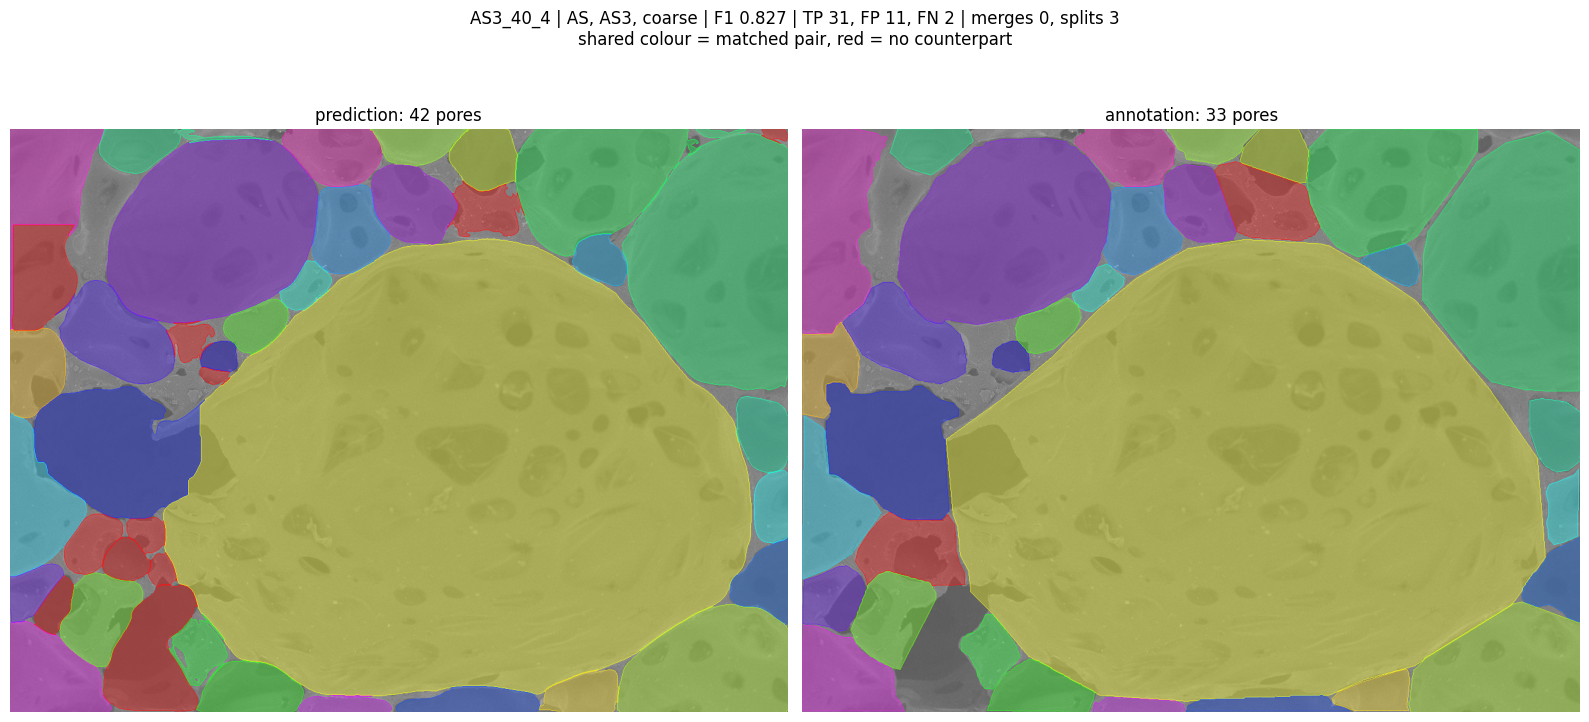

In [18]:
sample = source.load(80)
labels = predict(segmenter, sample)
comparison_figure(sample, labels) 

## Inspection original micro-sam on the same set

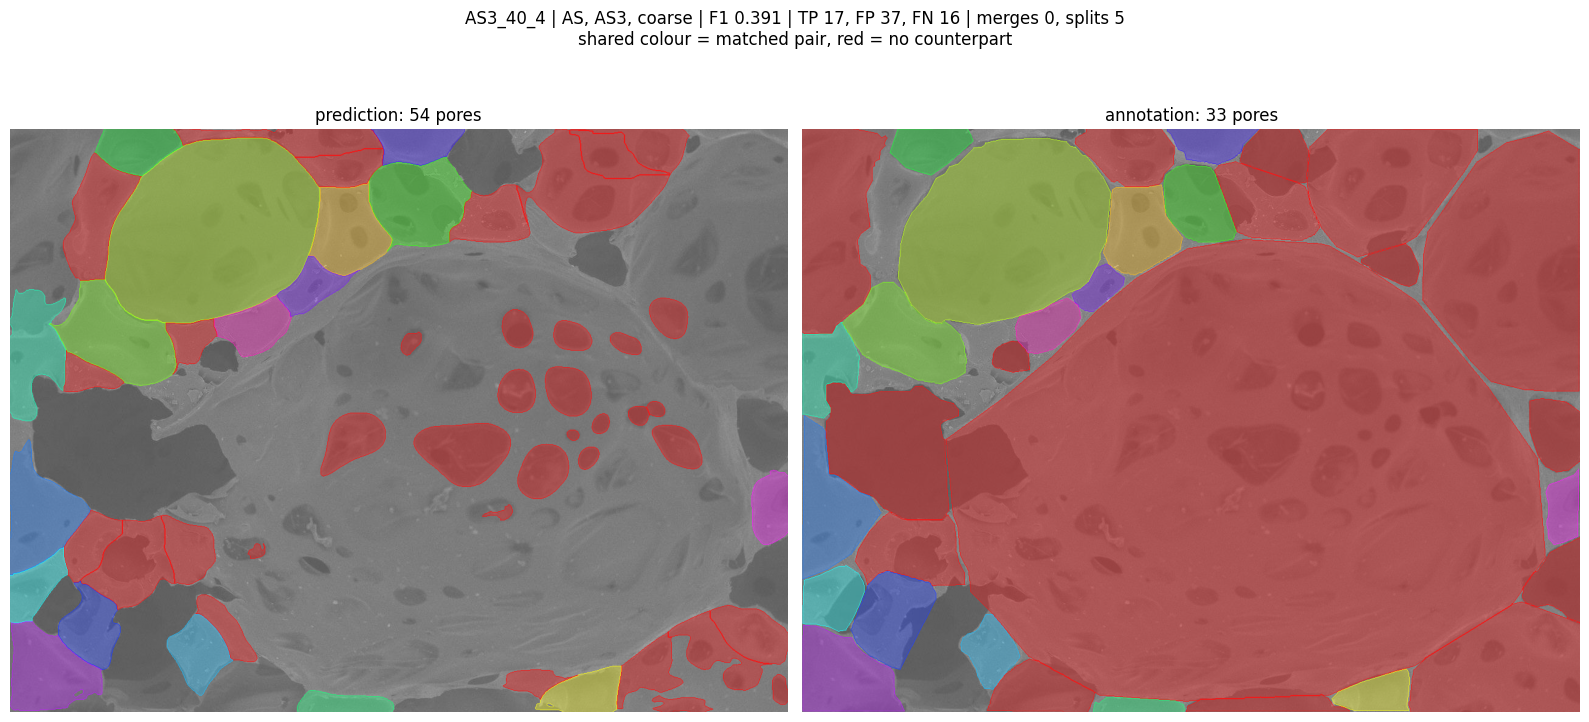

In [19]:
from materials_vision.inspection import load_pretrained_segmenter, predict, comparison_figure

base_segmenter = load_pretrained_segmenter() 

sample = source.load(80)
base_labels = predict(base_segmenter, sample)
comparison_figure(sample, base_labels)

# Metrics evaluation

## Metric definitions

All metrics compare the model's instance masks with the manual annotation on the same images. A predicted pore and an annotated pore are **matched** when their mask IoU is at least 0.5; each pore can be matched at most once. Close-up images are excluded. Bars are shown for all images together (*overall*) and separately for each material (AS, K, VAB).

### Detection and overlap
- **F1 (pooled)**: harmonic mean of precision and recall, with true positives, false positives and false negatives summed over all images before dividing. The headline metric of the study.
- **Precision**: fraction of predicted pores that match an annotated pore.
- **Recall**: fraction of annotated pores that are matched by a prediction.
- **F1 (mean over images)**: F1 computed per image and then averaged, so every image weighs the same regardless of how many pores it holds.
- **IoU of matched pairs**: mean mask overlap of the matched pairs; how accurately the pores that were found are outlined.
- **Boundary F1 (tolerance 0.1)**: agreement between predicted and annotated pore outlines, where an outline pixel counts as correct if it lies within 0.1 × the mean annotated pore diameter of an outline pixel on the other side.

### Recall by pore size
- **Recall, Q1–Q4**: recall computed separately for four pore size classes, from the smallest (Q1) to the largest (Q4). The class edges are quartiles of annotated pore area in µm², fixed on the training set, so a class means the same physical size on both microscopes. Pores touching the image edge are included.

### Separation of neighbouring pores
- **Merges per 100 pores**: predictions that cover at least half of each of two or more annotated pores, i.e. neighbouring pores fused into one.
- **Splits per 100 pores**: annotated pores that contain at least half of each of two or more predictions, i.e. one pore cut into several.

### Shape of matched pores
Computed only on matched pairs, excluding pores that touch the image edge.
- **Size bias**: median ratio of predicted to annotated equivalent diameter, as a signed percentage. Positive means the model draws the pores it finds too large.
- **Diameter error**: median absolute relative difference in equivalent diameter, |d_pred − d_gt| / d_gt.
- **Elongation error**: median absolute relative difference in elongation (major-to-minor axis ratio of the fitted ellipse).
- **Angle error**: median difference in orientation of the fitted ellipse, in degrees (0–90), counted only for pores elongated enough for an orientation to be meaningful.

### Material quantities (prediction relative to annotation)
Signed, as (prediction − annotation) / annotation × 100%; closer to zero is better. Unlike the shape metrics, these use **all** instances, matched or not: they show how far a reported material property would move if the manual annotation were replaced by the model.
- **Pore count**: total predicted pores relative to annotated pores. Positive means over-counting. (Pore number density per mm² gives exactly the same number, so it is not shown separately.)
- **Porosity**: areal fraction of the image covered by pores, averaged over images. Note that the annotation often draws neighbouring pores as touching, so this is porosity by the annotation convention, not physical porosity.
- **Median pore diameter**: shift of the median equivalent diameter of the pore size distribution (pores touching the image edge excluded).
- **Spread of pore diameter (IQR)**: change of the interquartile range of the same distribution; separates a distribution that spread from one that shifted.
- **Diameter distribution distance**: Wasserstein distance between the predicted and annotated diameter distributions (the average shift needed to turn one into the other), as a percentage of the annotated median diameter. Unsigned; lower is better.

### Orientation distribution
Computed on elongated pores that do not touch the image edge.
- **Mean orientation difference**: difference between the mean pore orientation of prediction and annotation, in degrees. Only meaningful when the pores have a clear preferred direction.
- **Alignment strength difference**: prediction minus annotation in the axial resultant length, which runs from 0 (orientations spread evenly) to 1 (all pores aligned). Positive means the model makes pores look more aligned than they are.


In [1]:
from materials_vision.evaluation.size_bins import load_size_bins
from materials_vision.inspection import (load_pretrained_segmenter,
                                         load_segmenter, metric_figures,
                                         metrics_table, score_model,
                                         scores_by_material)
from pathlib import Path
from materials_vision.training import build_source
%matplotlib inline

I0000 00:00:1790433936.426848  235828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790433936.508100  235828 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/dwalicki/Projekty/MaterialsVision/.venv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
I0000 00:00:1790433938.030036  235828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-p

In [2]:
size_bins = load_size_bins(Path("/home/dwalicki/dane/splits/size_bins_v1.json"))

In [3]:
source = build_source(
    Path("/home/dwalicki/dane/splits/split_v1.csv"),
    Path("/home/dwalicki/dane/manifests/v3/manifest_v3.csv"),
    "test", allow_test=True,
)

TEST UNLOCKED: reading 106 image(s) of split split_v1. This must be the single, final evaluation.


In [4]:
finetuned = load_segmenter(Path(
    "/home/dwalicki/Projekty/MaterialsVision/checkpoints/final/"
    "checkpoints/full_b_trainval_seed20260907/epoch-12.pt"
))

Replaced ResizeLongestSide.apply_image_torch: the library computes the target size from the batch and channel axes, which squeezes every three-channel image to 341x1024. The replacement reads height and width, so a (960, 1280) image reaches the encoder as (768, 1024).


In [5]:
base = load_pretrained_segmenter()

In [6]:
evaluations = {
    "vit_l_lm (before fine-tuning)": score_model(base, source, size_bins),
    "fine-tuned (epoch 12)": score_model(finetuned, source, size_bins),
}

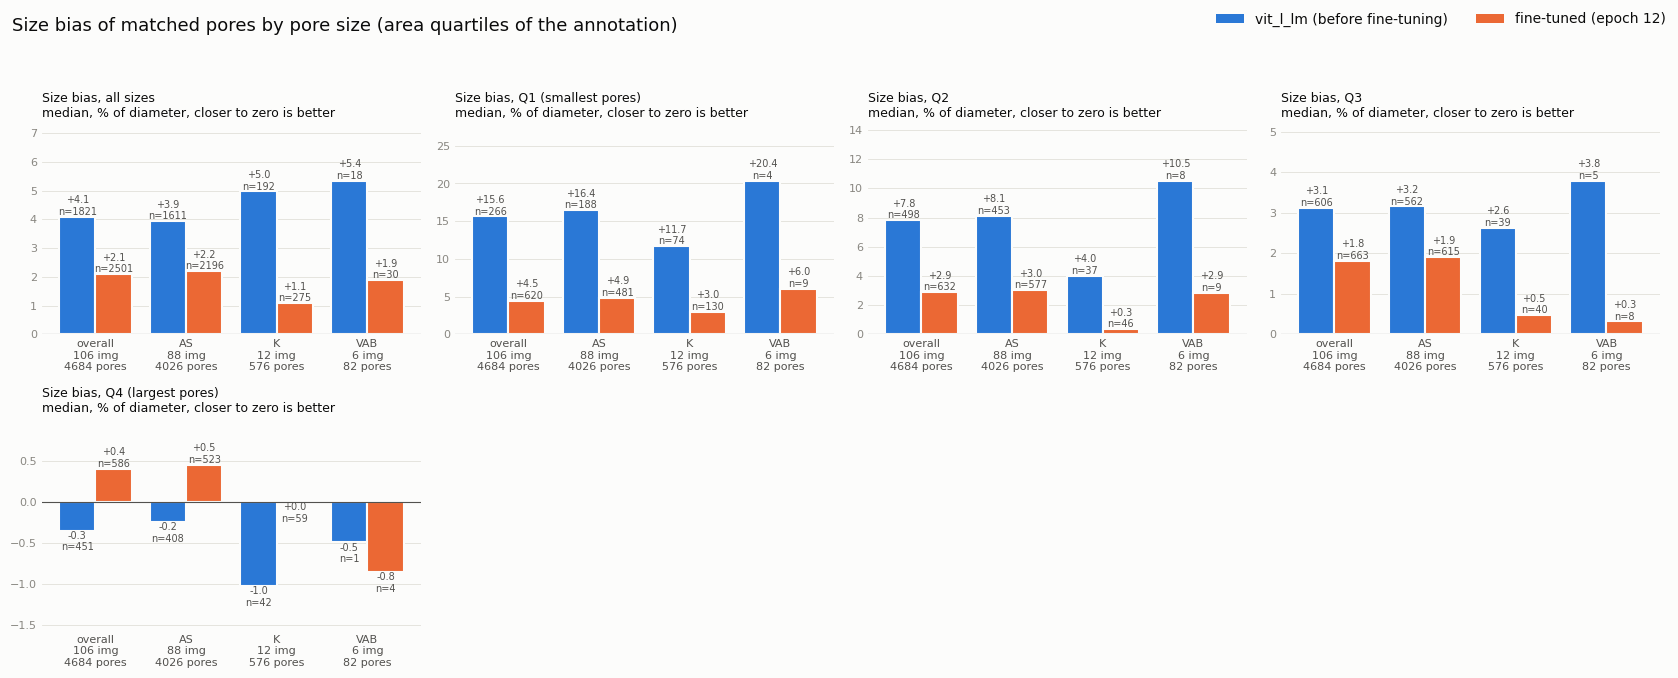

In [8]:
scores = {name: scores_by_material(ev, size_bins)
          for name, ev in evaluations.items()}
figures = metric_figures(scores)
figures["size_bias"]

In [ ]:
figures = metric_figures(scores) 
figures["detection"]
metrics_table(scores)  

subset                                                                                                           overall  \
model                                                                                      vit_l_lm (before fine-tuning)   
section     metric                            unit                                                                         
detection   F1 (pooled)                                                                                         0.597061   
            Precision                                                                                           0.579317   
            Recall                                                                                              0.615927   
            F1 (mean over images)                                                                               0.560958   
            IoU of matched pairs                                                                                0.811427   
            Boundary F1 (tolerance 0.1)                                                                         0.690817   
size        Recall, Q1 (smallest pores)                                                                         0.358367   
            Recall, Q2                                                                                          0.708370   
            Recall, Q3                                                                                          0.792062   
            Recall, Q4 (largest pores)                                                                          0.621459   
separation  Merges                            per 100 annotated pores                                           2.647310   
            Splits                            per 100 annotated pores                                           9.308284   
shape       Size bias of matched pores        % of diameter                                                     4.088825   
            Diameter error of matched pores   median, % of diameter                                             6.075854   
            Elongation error of matched pores median, % of elongation                                           5.342305   
            Angle error of matched pores      median, degrees                                                   4.735185   
material    Pore count                        % of annotated                                                    6.319385   
            Porosity                          % of annotated                                                  -24.274007   
            Median pore diameter              % of annotated                                                    6.765225   
            Spread of pore diameter (IQR)     % of annotated                                                  -21.323086   
            Diameter distribution distance    Wasserstein, % of annotated median                               14.299682   
orientation Mean orientation difference       degrees; read only where alignment is high                        5.573898   
            Alignment strength difference     axial resultant, prediction minus annotation                     -0.039254   

subset                                                                                                            \
model                                                                                      fine-tuned (epoch 12)   
section     metric                            unit                                                                 
detection   F1 (pooled)                                                                                 0.851867   
            Precision                                                                                   0.807692   
            Recall                                                                                      0.901153   
            F1 (mean over images)                                              

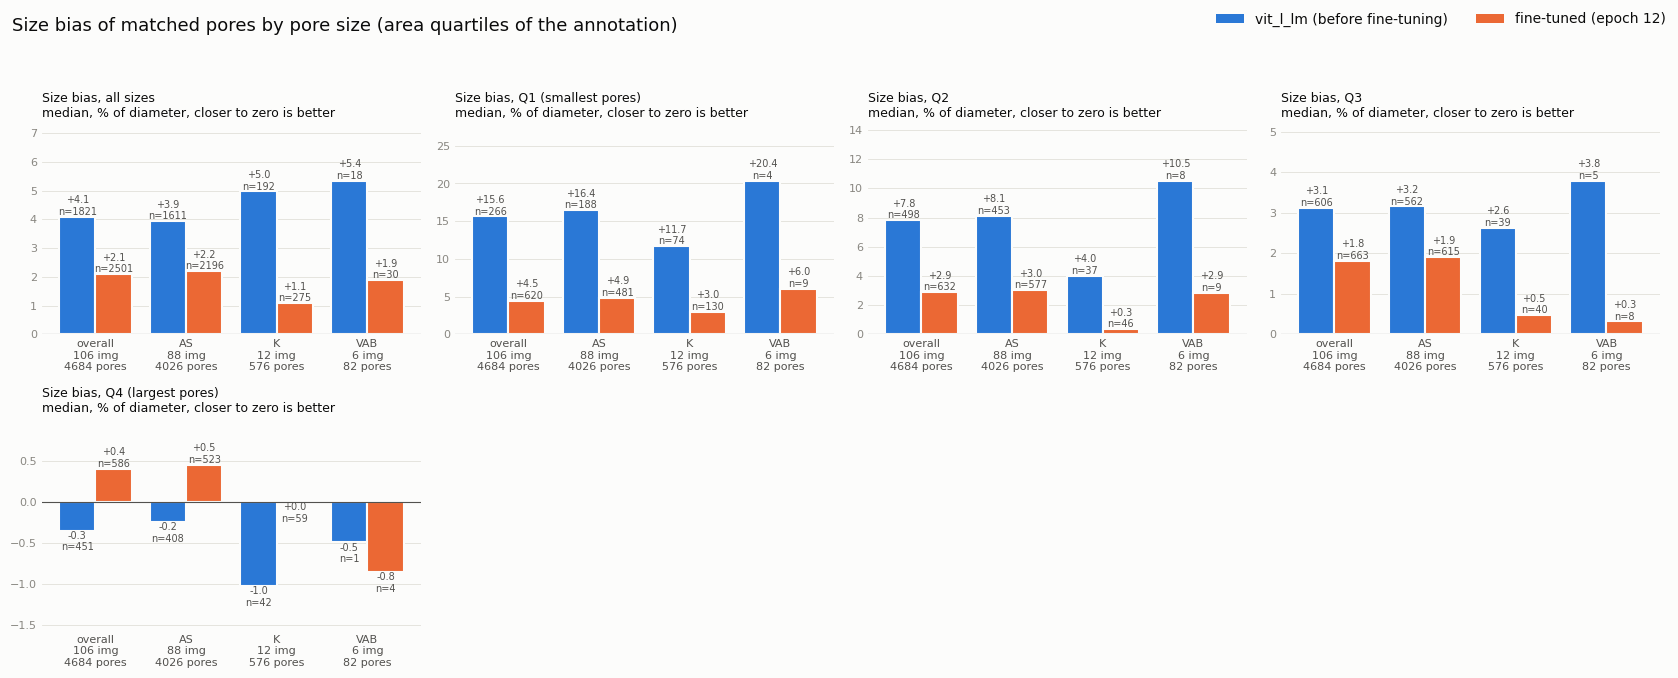

In [11]:
scores = {name: scores_by_material(ev, size_bins)
          for name, ev in evaluations.items()}
figures = metric_figures(scores)
figures["size_bias"]